In [2]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.11/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.11/site-packages', '/home/bergerot/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python311.zip', '/usr/lib/python3.11', '/usr/lib/python3.11/lib-dynload', '', '/usr/local/lib/python3.11/dist-packages', '/usr/lib/python3/dist-packages', '/usr/lib/python3.11/dist-packages']


In [3]:
import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *

import pandas as pd
import seaborn as sns

/home/bergerot/Documents/PhD/Code/DistRLdynamics/../CRLDenv/lib/python3.11/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [4]:
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Environments.EcologicalPublicGood import EcologicalPublicGood
from pyCRLD.Utils import FlowPlot as fp

import numpy as np
import itertools as it
import matplotlib.pyplot as plt
from pyCRLD.Utils.Helpers import compute_stationarydistribution

from datetime import datetime

In [5]:
from DistBase import distbase

In [6]:
# Define environment
env = EcologicalPublicGood(N=2, f=1.2, c=5, m=-4, qc=0.2, qr=0.1, degraded_choice=True)
env

EcologicalPublicGood_2_1.2_5_-4_0.2_0.1_DegChoi

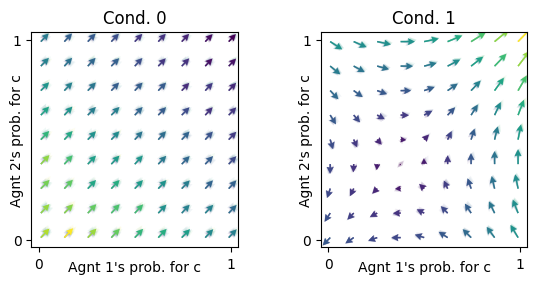

In [7]:
# Init enviornment and MultiAgentEnvironment-interface
mae = stratAC(env=env, learning_rates=0.1, discount_factors=0.9, use_prefactor=True)

x = ([0], [0,1], [0])  # Plotting only the prosperous state
y = ([1], [0,1], [0])  # Plotting only the prosperous state
ax = fp.plot_strategy_flow(mae, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16)

In [29]:
def compute_error(Xs, bin_nrs, sigmas, lr, gamma, path, version):
    for i, nr in enumerate(bin_nrs):
        errors = np.zeros((len(sigmas), len(Xs)))
        for j, sigma in enumerate(sigmas):
            print("Bin number "+str(nr)+", sigma="+str(sigma))
            db = distbase(env, nr_reward_bins=nr, 
                          discretization_sigma=sigma, learning_rates=lr, discount_factors=gamma)
            for k, x in enumerate(Xs):
                distRPE = db.TDerror(x, norm=True)
                detRPE = mae.TDerror(x, norm=True)
                error = np.linalg.norm(detRPE[:,1,:]-distRPE[:,1,:])  # error in degraded env
                errors[j, k] = error
        index = ["sig="+str(sigma) for sigma in sigmas]
        columns = ["x="+str(x) for x in np.linspace(0, 1, len(Xs))]
        df = pd.DataFrame(errors, index=index, columns=columns)
        df.to_csv(path+"error_df_"+str(nr)+"_bins_"+version+".csv")
    return df

In [8]:
# Initialization
path = "data/error_calculation/"
version = "2024-05-22-v0.0"
lr = 0.1
gamma = 0.9
bin_nrs = np.linspace(4, 30, 27).astype(int)
sigmas = np.linspace(0.05, 2, 40)
Xs = []
Pc = np.linspace(0, 1, 101)
Pc[0] = 0.001
Pc[-1] = 0.999
for i, p in enumerate(Pc):
    Xisa = np.zeros((2, 2, 2))
    Xisa[:, :, 0] = p
    Xisa[:, :, 1] = 1-p
    Xisa[:, 0, :] = .5
    Xs.append(Xisa)

In [33]:
Xs[0][:, 1, 0]

array([0.001, 0.001])

In [34]:
errors = compute_error(Xs, bin_nrs, sigmas, lr, gamma, path, version)

Bin number 4, sigma=0.05
Bin number 4, sigma=0.1
Bin number 4, sigma=0.15
Bin number 4, sigma=0.2
Bin number 4, sigma=0.25
Bin number 4, sigma=0.3
Bin number 4, sigma=0.35
Bin number 4, sigma=0.39999999999999997
Bin number 4, sigma=0.44999999999999996
Bin number 4, sigma=0.49999999999999994
Bin number 4, sigma=0.5499999999999999
Bin number 4, sigma=0.6
Bin number 4, sigma=0.65
Bin number 4, sigma=0.7
Bin number 4, sigma=0.75
Bin number 4, sigma=0.7999999999999999
Bin number 4, sigma=0.85
Bin number 4, sigma=0.9
Bin number 4, sigma=0.95
Bin number 4, sigma=1.0
Bin number 4, sigma=1.0499999999999998
Bin number 4, sigma=1.0999999999999999
Bin number 4, sigma=1.15
Bin number 4, sigma=1.2
Bin number 4, sigma=1.25
Bin number 4, sigma=1.3
Bin number 4, sigma=1.3499999999999999
Bin number 4, sigma=1.4
Bin number 4, sigma=1.45
Bin number 4, sigma=1.5
Bin number 4, sigma=1.5499999999999998
Bin number 4, sigma=1.5999999999999999
Bin number 4, sigma=1.65
Bin number 4, sigma=1.7
Bin number 4, sigma

Bin number 11, sigma=0.2
Bin number 11, sigma=0.25
Bin number 11, sigma=0.3
Bin number 11, sigma=0.35
Bin number 11, sigma=0.39999999999999997
Bin number 11, sigma=0.44999999999999996
Bin number 11, sigma=0.49999999999999994
Bin number 11, sigma=0.5499999999999999
Bin number 11, sigma=0.6
Bin number 11, sigma=0.65
Bin number 11, sigma=0.7
Bin number 11, sigma=0.75
Bin number 11, sigma=0.7999999999999999
Bin number 11, sigma=0.85
Bin number 11, sigma=0.9
Bin number 11, sigma=0.95
Bin number 11, sigma=1.0
Bin number 11, sigma=1.0499999999999998
Bin number 11, sigma=1.0999999999999999
Bin number 11, sigma=1.15
Bin number 11, sigma=1.2
Bin number 11, sigma=1.25
Bin number 11, sigma=1.3
Bin number 11, sigma=1.3499999999999999
Bin number 11, sigma=1.4
Bin number 11, sigma=1.45
Bin number 11, sigma=1.5
Bin number 11, sigma=1.5499999999999998
Bin number 11, sigma=1.5999999999999999
Bin number 11, sigma=1.65
Bin number 11, sigma=1.7
Bin number 11, sigma=1.75
Bin number 11, sigma=1.7999999999999

Bin number 17, sigma=1.9
Bin number 17, sigma=1.95
Bin number 17, sigma=2.0
Bin number 18, sigma=0.05
Bin number 18, sigma=0.1
Bin number 18, sigma=0.15
Bin number 18, sigma=0.2
Bin number 18, sigma=0.25
Bin number 18, sigma=0.3
Bin number 18, sigma=0.35
Bin number 18, sigma=0.39999999999999997
Bin number 18, sigma=0.44999999999999996
Bin number 18, sigma=0.49999999999999994
Bin number 18, sigma=0.5499999999999999
Bin number 18, sigma=0.6
Bin number 18, sigma=0.65
Bin number 18, sigma=0.7
Bin number 18, sigma=0.75
Bin number 18, sigma=0.7999999999999999
Bin number 18, sigma=0.85
Bin number 18, sigma=0.9
Bin number 18, sigma=0.95
Bin number 18, sigma=1.0
Bin number 18, sigma=1.0499999999999998
Bin number 18, sigma=1.0999999999999999
Bin number 18, sigma=1.15
Bin number 18, sigma=1.2
Bin number 18, sigma=1.25
Bin number 18, sigma=1.3
Bin number 18, sigma=1.3499999999999999
Bin number 18, sigma=1.4
Bin number 18, sigma=1.45
Bin number 18, sigma=1.5
Bin number 18, sigma=1.5499999999999998


Bin number 24, sigma=1.65
Bin number 24, sigma=1.7
Bin number 24, sigma=1.75
Bin number 24, sigma=1.7999999999999998
Bin number 24, sigma=1.8499999999999999
Bin number 24, sigma=1.9
Bin number 24, sigma=1.95
Bin number 24, sigma=2.0
Bin number 25, sigma=0.05
Bin number 25, sigma=0.1
Bin number 25, sigma=0.15
Bin number 25, sigma=0.2
Bin number 25, sigma=0.25
Bin number 25, sigma=0.3
Bin number 25, sigma=0.35
Bin number 25, sigma=0.39999999999999997
Bin number 25, sigma=0.44999999999999996
Bin number 25, sigma=0.49999999999999994
Bin number 25, sigma=0.5499999999999999
Bin number 25, sigma=0.6
Bin number 25, sigma=0.65
Bin number 25, sigma=0.7
Bin number 25, sigma=0.75
Bin number 25, sigma=0.7999999999999999
Bin number 25, sigma=0.85
Bin number 25, sigma=0.9
Bin number 25, sigma=0.95
Bin number 25, sigma=1.0
Bin number 25, sigma=1.0499999999999998
Bin number 25, sigma=1.0999999999999999
Bin number 25, sigma=1.15
Bin number 25, sigma=1.2
Bin number 25, sigma=1.25
Bin number 25, sigma=1.3

In [10]:
# Retrieve data and put it in array
errors = np.zeros((len(bin_nrs), len(sigmas), len(Xs)))
for i, nr in enumerate(bin_nrs):
    df = pd.read_csv(path+"error_df_"+str(nr)+"_bins_"+version+".csv")
    npdf = df.to_numpy()
    errors[i, :, :] = npdf[:, 1:]

In [11]:
mean_error = np.mean(errors, axis=2)
palette = sns.color_palette("viridis_r", len(bin_nrs))

Text(0, 0.5, 'mean error')

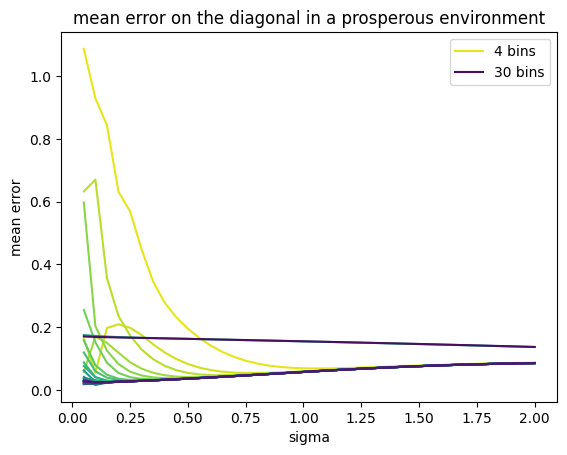

In [13]:
# Plot errors as curves

plt.figure()
for j, nr in enumerate(bin_nrs):
    if nr==4 or nr==30:
        plt.plot(sigmas, mean_error[j, :], color=palette[j], label=str(nr)+" bins")
    else:
        plt.plot(sigmas, mean_error[j, :], color=palette[j])
plt.xlabel("sigma")
plt.legend()
plt.title("mean error on the diagonal in a prosperous environment")
plt.ylabel("mean error")

Text(0, 0.5, 'mean error')

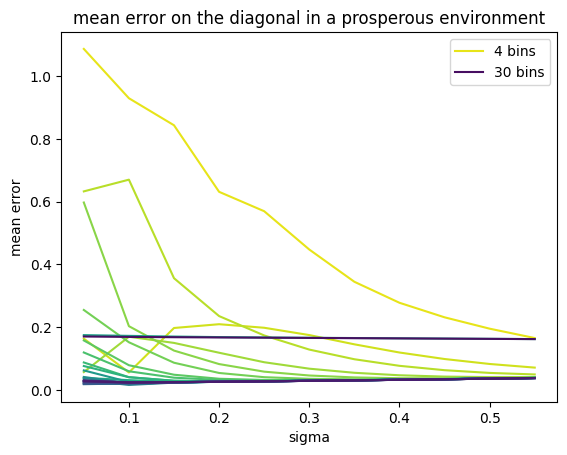

In [14]:
# Plot errors for small sigmas

plt.figure()
for j, nr in enumerate(bin_nrs):
    if nr==4 or nr==30:
        plt.plot(sigmas[:11], mean_error[j, :11], color=palette[j], label=str(nr)+" bins")
    else:
        plt.plot(sigmas[:11], mean_error[j, :11], color=palette[j])
plt.xlabel("sigma")
plt.legend()
plt.title("mean error on the diagonal in a prosperous environment")
plt.ylabel("mean error")

In [18]:
np.min(mean_error[:, :11])

0.01603126249248434

In [19]:
mean_error[:, :11]

array([[1.08662019, 0.92949532, 0.84335019, 0.63130328, 0.56952513,
        0.44746996, 0.34467617, 0.27777853, 0.2314643 , 0.19525177,
        0.16542396],
       [0.16346343, 0.05571995, 0.19743423, 0.20947282, 0.1981645 ,
        0.17489584, 0.14539225, 0.11930832, 0.09857828, 0.08277636,
        0.07120379],
       [0.63271894, 0.67004834, 0.35602118, 0.23536601, 0.17367059,
        0.12864442, 0.09786313, 0.07690057, 0.06297067, 0.05428301,
        0.0494354 ],
       [0.05697131, 0.16950013, 0.14989464, 0.11858509, 0.0883376 ,
        0.06778484, 0.05470766, 0.04677968, 0.04257306, 0.04096683,
        0.04104619],
       [0.59725648, 0.2032263 , 0.12544191, 0.0824626 , 0.05830801,
        0.04604937, 0.03993246, 0.03740707, 0.03705165, 0.03792084,
        0.03942353],
       [0.25483996, 0.1519081 , 0.08673401, 0.05410535, 0.04066287,
        0.03544883, 0.03390556, 0.03419567, 0.03540438, 0.03704173,
        0.03888422],
       [0.15774857, 0.07877057, 0.04851618, 0.03569978, 0.

Text(0.5, 1.0, 'Prosperous environment')

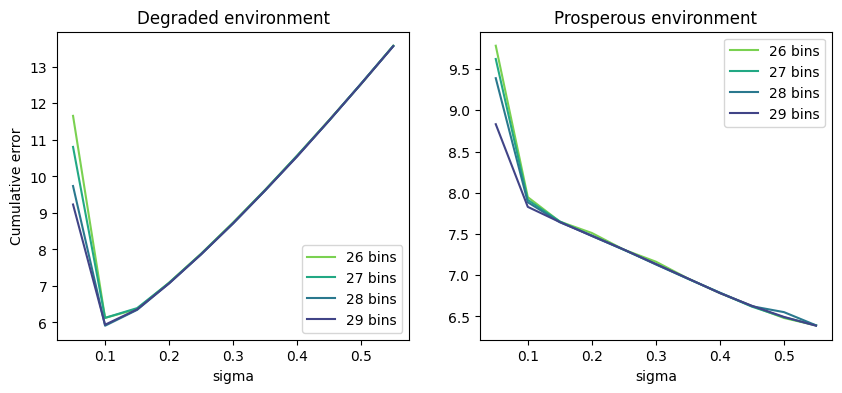

In [60]:
# Plot errors for small sigmas, large number of bins
palette2 = sns.color_palette("viridis_r", 4)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
axes = [ax1, ax2]
for i, ax in enumerate(axes):
    for j, nr in enumerate(bin_nrs[-5:-1]):
        ax.plot(sigmas[:11], errors[i, nr-4, :11], label=str(nr)+" bins", color=palette2[j])
        ax.set_xlabel("sigma")
        ax.legend()
ax1.set_title("Degraded environment")
ax1.set_ylabel("Cumulative error")
ax2.set_title("Prosperous environment")

Text(0.5, 1.0, 'Prosperous environment')

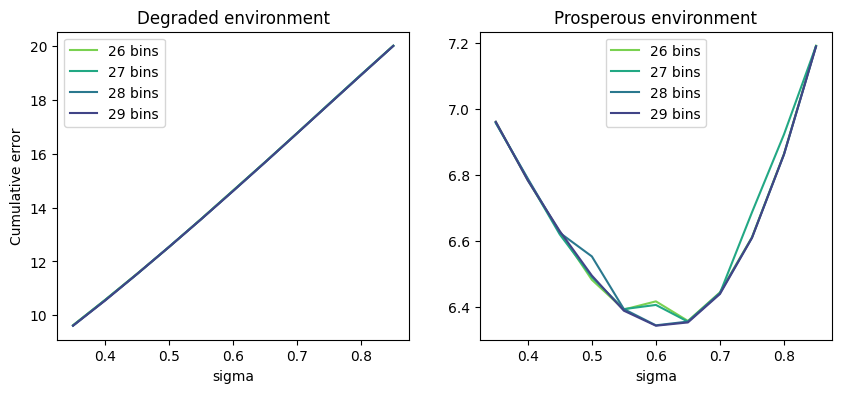

In [56]:
# Plot errors for intermediate sigmas, large number of bins
palette2 = sns.color_palette("viridis_r", 4)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
axes = [ax1, ax2]
for i, ax in enumerate(axes):
    for j, nr in enumerate(bin_nrs[-5:-1]):
        ax.plot(sigmas[6:17], errors[i, nr-4, 6:17], label=str(nr)+" bins", color=palette2[j])
        ax.set_xlabel("sigma")
        ax.legend()
ax1.set_title("Degraded environment")
ax1.set_ylabel("Cumulative error")
ax2.set_title("Prosperous environment")

In [64]:
# Compute error along the policy diagonal
def compute_error_diagonal(Xs, bin_nr, sigma, lr, gamma, path, version):
    errors = np.zeros((2, len(Xs)))
    db = distbase(env, nr_reward_bins=bin_nr, 
                  discretization_sigma=sigma, learning_rates=lr, discount_factors=gamma)
    for k, x in enumerate(Xs):
        distRPE = db.TDerror(x)
        detRPE = mae.TDerror(x)
        error_d = np.linalg.norm(detRPE[:,0,:]-distRPE[:,0,:])
        error_p = np.linalg.norm(detRPE[:,1,:]-distRPE[:,1,:])
        errors[0, k] += error_d
        errors[1, k] += error_p
    index = ["degraded", "prosperous"]
    columns = ["X="+str(x) for x in Xs]
    df = pd.DataFrame(errors, index=index, columns=columns)
    df.to_csv(path+"error_diagonal_df_"+str(bin_nr)+"_bins_sigma"+str(sigma)+"_"+version+".csv")
    return df

In [11]:
# Initialization
path = "data/error_calculation/"
version = "2024-04-26-v0.0"
lr = 0.1
gamma = 0.9
bin_nr = 29
sigmas = [0.1, 0.6]
Xs = []
Pc = np.linspace(0, 1, 101)
Pc[0] = 0.001
Pc[-1] = 0.999
for i, p in enumerate(Pc):
    Xisa = np.zeros((2, 2, 2))
    Xisa[:, :, 0] = p
    Xisa[:, :, 1] = 1-p
    Xs.append(Xisa)

In [66]:
for i, sigma in enumerate(sigmas):
    df = compute_error_diagonal(Xs, bin_nr, sigma, lr, gamma, path, version)

In [12]:
# Retrieve data and put it in array
xaxis = np.linspace(0, 1, 101)
errors = np.zeros((2, len(xaxis)))
sigma = 0.1
df = pd.read_csv(path+"error_diagonal_df_"+str(bin_nr)+"_bins_sigma"+str(sigma)+"_"+version+".csv")
npdf = df.to_numpy()
errors[0, :] = npdf[0][1:]
errors[1, :] = npdf[1][1:]

In [13]:
errors_2 = np.zeros((2, len(xaxis)))
sigma = 0.6
df = pd.read_csv(path+"error_diagonal_df_"+str(bin_nr)+"_bins_sigma"+str(sigma)+"_"+version+".csv")
npdf = df.to_numpy()
errors_2[0, :] = npdf[0][1:]
errors_2[1, :] = npdf[1][1:]

Text(0.5, 1.0, 'Prosperous environment')

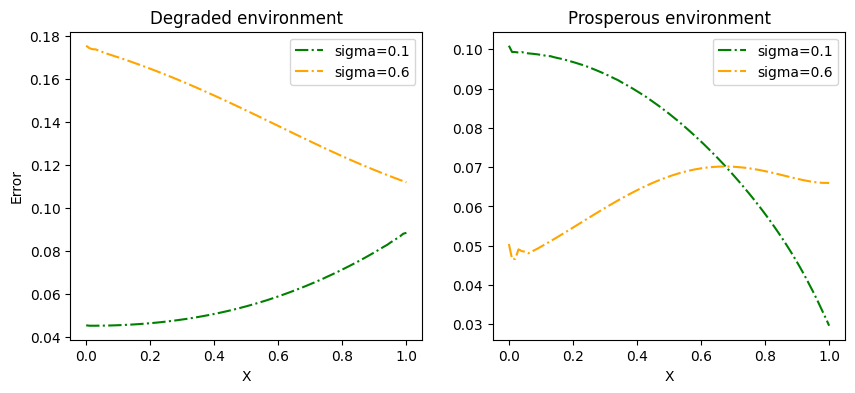

In [14]:
# Plot errors as curves

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
axes = [ax1, ax2]
for i, ax in enumerate(axes):
    ax.plot(xaxis, errors[i, :], color="green", ls='dashdot', label='sigma=0.1')
    ax.plot(xaxis, errors_2[i, :], color="orange", ls='dashdot', label='sigma=0.6')
    ax.set_xlabel("X")
    ax.legend()
ax1.set_title("Degraded environment")
ax1.set_ylabel("Error")
ax2.set_title("Prosperous environment")
# ax2.legend()

In [15]:
np.sum(errors[1, :]), np.sum(errors_2[1, :])

(7.829680182039734, 6.3425483182072595)

In [80]:
path = "data/error_calculation/"
version = "2024-04-22-v0.0"
lr = 0.1
gamma = 0.9
bin_nrs = np.linspace(4, 30, 27).astype(int)
sigmas = np.linspace(0.05, 2, 40)
Xs = []
Pc = np.linspace(0, 1, 101)
Pc[0] = 0.001
Pc[-1] = 0.999
for i, p in enumerate(Pc):
    Xisa = np.zeros((2, 2, 2))
    Xisa[:, :, 0] = p
    Xisa[:, :, 1] = 1-p
    Xs.append(Xisa)

In [81]:
# Retrieve data and put it in array
errors = np.zeros((2, len(bin_nrs), len(sigmas)))
for i, nr in enumerate(bin_nrs):
    df = pd.read_csv(path+"error_df_"+str(nr)+"_bins_"+version+".csv")
    npdf = df.to_numpy()
    errors[0, i, :] = npdf[0][1:]
    errors[1, i, :] = npdf[1][1:]

In [91]:
palette_even = sns.color_palette("flare", 14)
palette_odd = sns.color_palette("crest", 13)

Text(0.5, 1.0, 'Prosperous environment')

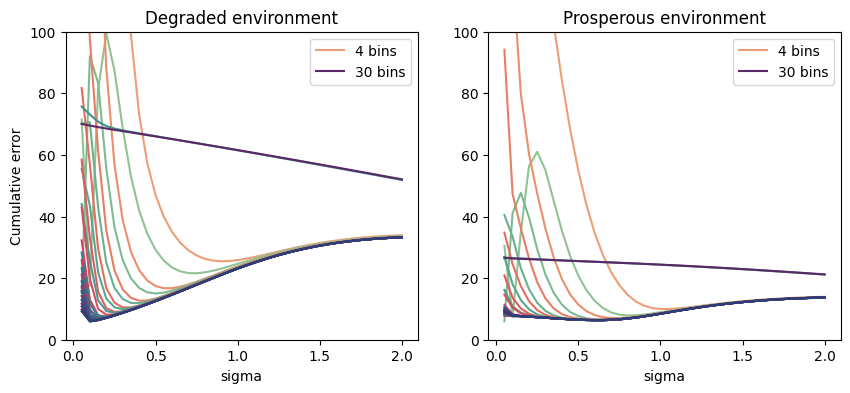

In [93]:
# Plot errors as curves

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
axes = [ax1, ax2]
for i, ax in enumerate(axes):
    for j, nr in enumerate(bin_nrs):
        if nr==4 or nr==30:
            ax.plot(sigmas, errors[i, j, :], color=palette_even[int(nr/2 - 2)], label=str(nr)+" bins")
        else:
            if nr%2==0:
                palette = palette_even
                idx = int(nr/2 - 2)
            else:
                palette = palette_odd
                idx = int((nr-1)/2 - 2)
            ax.plot(sigmas, errors[i, j, :], color=palette[idx])
        ax.set_xlabel("sigma")
        ax.legend()
ax1.set_ylim([0, 100])
ax2.set_ylim([0, 100])
ax1.set_title("Degraded environment")
ax1.set_ylabel("Cumulative error")
ax2.set_title("Prosperous environment")
# ax2.legend()

Text(0.5, 1.0, 'Prosperous environment')

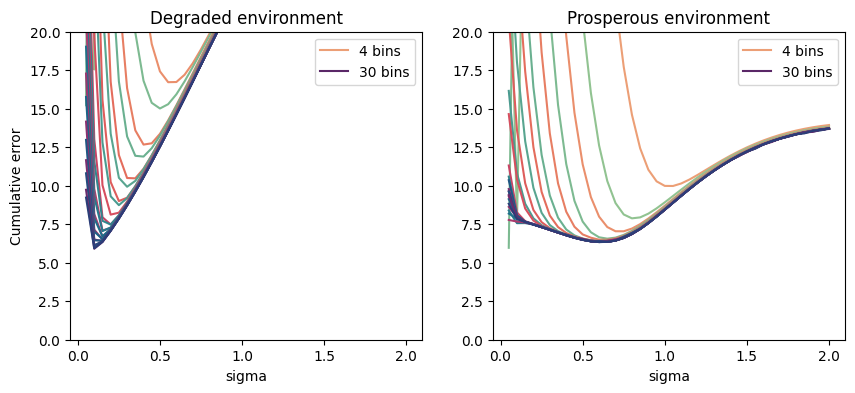

In [94]:
# Plot errors as curves

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
axes = [ax1, ax2]
for i, ax in enumerate(axes):
    for j, nr in enumerate(bin_nrs):
        if nr==4 or nr==30:
            ax.plot(sigmas, errors[i, j, :], color=palette_even[int(nr/2 - 2)], label=str(nr)+" bins")
        else:
            if nr%2==0:
                palette = palette_even
                idx = int(nr/2 - 2)
            else:
                palette = palette_odd
                idx = int((nr-1)/2 - 2)
            ax.plot(sigmas, errors[i, j, :], color=palette[idx])
        ax.set_xlabel("sigma")
        ax.legend()
ax1.set_ylim([0, 20])
ax2.set_ylim([0, 20])
ax1.set_title("Degraded environment")
ax1.set_ylabel("Cumulative error")
ax2.set_title("Prosperous environment")
# ax2.legend()

Text(0.5, 1.0, 'Prosperous environment')

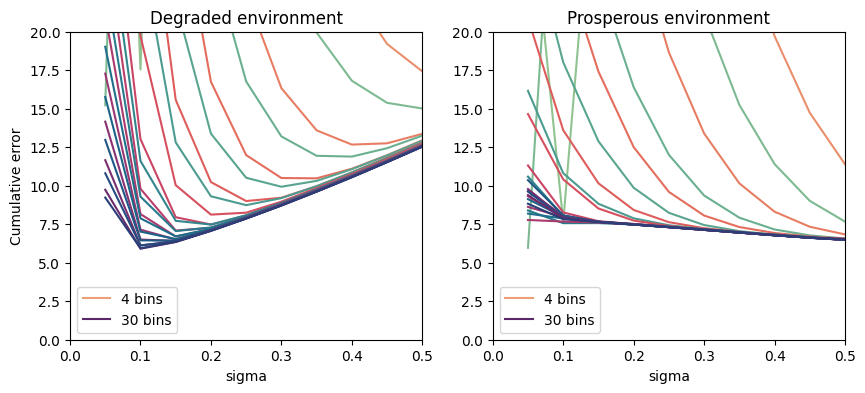

In [95]:
# Plot errors as curves

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
axes = [ax1, ax2]
for i, ax in enumerate(axes):
    for j, nr in enumerate(bin_nrs):
        if nr==4 or nr==30:
            ax.plot(sigmas, errors[i, j, :], color=palette_even[int(nr/2 - 2)], label=str(nr)+" bins")
        else:
            if nr%2==0:
                palette = palette_even
                idx = int(nr/2 - 2)
            else:
                palette = palette_odd
                idx = int((nr-1)/2 - 2)
            ax.plot(sigmas, errors[i, j, :], color=palette[idx])
        ax.set_xlabel("sigma")
        ax.legend()
ax1.set_ylim([0, 20])
ax2.set_ylim([0, 20])
ax1.set_xlim([0, 0.5])
ax2.set_xlim([0, 0.5])
ax1.set_title("Degraded environment")
ax1.set_ylabel("Cumulative error")
ax2.set_title("Prosperous environment")
# ax2.legend()

Text(0.5, 1.0, 'Prosperous environment')

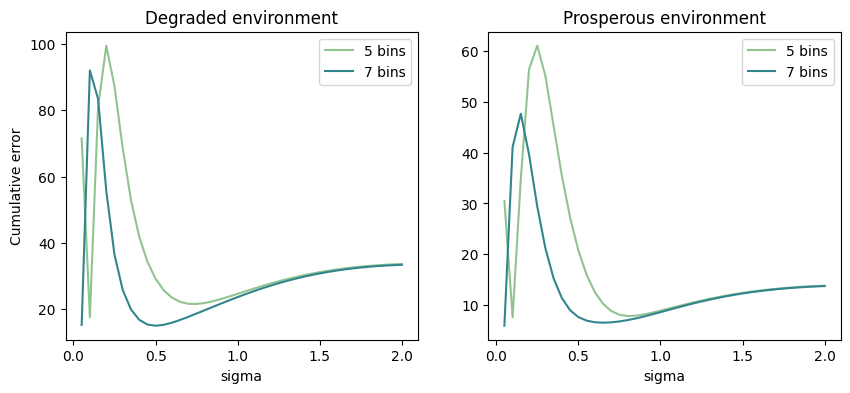

In [103]:
# Plot errors as curves

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
axes = [ax1, ax2]
for i, ax in enumerate(axes):
    ax.plot(sigmas, errors[i, 1, :], color=palette_odd[0], label="5 bins")
    ax.plot(sigmas, errors[i, 3, :], color=palette_odd[6], label="7 bins")
    ax.set_xlabel("sigma")
    ax.legend()
ax1.set_title("Degraded environment")
ax1.set_ylabel("Cumulative error")
ax2.set_title("Prosperous environment")
# ax2.legend()

In [17]:
# Compute error but only for coop probability

def compute_error_coop(Xs, bin_nrs, sigmas, lr, gamma, path, version):
    for i, nr in enumerate(bin_nrs):
        errors = np.zeros((2, len(sigmas)))
        for j, sigma in enumerate(sigmas):
            print("Bin number "+str(nr)+", sigma="+str(sigma))
            db = distbase(env, nr_reward_bins=nr, 
                          discretization_sigma=sigma, learning_rates=lr, discount_factors=gamma)
            for k, x in enumerate(Xs):
                distRPE = db.TDerror(x)
                detRPE = mae.TDerror(x)
                error_d = np.linalg.norm(detRPE[:,0,0]-distRPE[:,0,0])  # error in degraded env
                error_p = np.linalg.norm(detRPE[:,1,0]-distRPE[:,1,0])  # error in prosperous env
                errors[0, j] += error_d
                errors[1, j] += error_p
        index = ["degraded", "prosperous"]
        columns = ["sig="+str(sigma) for sigma in sigmas]
        df = pd.DataFrame(errors, index=index, columns=columns)
        df.to_csv(path+"error_df_"+str(nr)+"_bins_"+version+".csv")
    return df

In [20]:
# Initialization
path = "data/error_calculation/"
version = "2024-05-17-v0.0"
lr = 0.1
gamma = 0.9
bin_nrs = np.array([29])
sigmas = np.array([0.1, 0.6])
Xs = []
Pc = np.linspace(0, 1, 101)
Pc[0] = 0.001
Pc[-1] = 0.999
for i, p in enumerate(Pc):
    Xisa = np.zeros((2, 2, 2))
    Xisa[:, :, 0] = p
    Xisa[:, :, 1] = 1-p
    Xs.append(Xisa)

In [21]:
errors_coop = compute_error_coop(Xs, bin_nrs, sigmas, lr, gamma, path, version)

Bin number 29, sigma=0.1
Bin number 29, sigma=0.6


In [22]:
errors_coop

,sig=0.1,sig=0.6
degraded,5.009452,11.870756
prosperous,3.449471,1.202230
